[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ChristofherdoVP/stokes-solar/blob/main/notebooks/03_campo_fraco.ipynb)

# Notebook 03 — Aproximação de campo fraco e seus limites

Acompanha as Seções 5.1 e 5.2 do artigo. Gera a Figura 4 do artigo e calcula o valor de $B$ a partir do qual o erro de $B_{LOS}$ passa de 10%.

Procedimento: sintetizamos perfis de Milne-Eddington com campo conhecido, aplicamos
$B_{LOS} = -\sum_k V_k I'_k / (C \sum_k I'^2_k)$ e comparamos com o valor verdadeiro.

In [1]:
# Executa também no Google Colab: clona o repositório se necessário
import sys, os, subprocess
if 'google.colab' in sys.modules and not os.path.exists('stokes-solar'):
    subprocess.run(['git', 'clone', '-q', 'https://github.com/ChristofherdoVP/stokes-solar.git'], check=True)
    os.chdir('stokes-solar/notebooks')

In [2]:
import sys; sys.path.insert(0, '..')
import numpy as np
import matplotlib.pyplot as plt
import stokespy as sp
from stokespy.estilo import setup, virgula, salvar, CORES, COLUNA
setup()

def janela(L, n_dl=12, npts=1201):
    dlD = sp.doppler_width(L['lam0'], 6000, 1.0, L['massa'])
    return L['lam0'] + np.linspace(-n_dl*dlD, n_dl*dlD, npts), dlD

def perfis(L, B, gamma_deg, eta0=10.0, a=0.15):
    lam, dlD = janela(L)
    S = sp.me_synthesis(lam, L['lam0'], L['g'], B, np.deg2rad(gamma_deg), 0.0,
                        vlos=0.0, dlD=dlD, eta0=eta0, a=a, S0=0.3, S1=0.7)
    return lam, S

## 1. $V$ e a previsão do campo fraco ($\gamma = 30°$, Fe I 630,25 nm)

In [3]:
L = sp.LINHAS['Fe I 630,25 nm']; C = sp.C_ZEEMAN * L['g'] * L['lam0']**2
for B in (100, 2000):
    lam, S = perfis(L, B, 30)
    b = sp.wfa_blos(lam, S[0], S[3], L['lam0'], L['g'])
    print(f'B = {B} G: B_LOS verdadeiro {B*np.cos(np.deg2rad(30)):.0f} G, recuperado {b:.0f} G')

B = 100 G: B_LOS verdadeiro 87 G, recuperado 87 G
B = 2000 G: B_LOS verdadeiro 1732 G, recuperado 927 G


## 2. Varredura em $B$ para três linhas ($\gamma = 0°$, sem ruído)

In [4]:
Bs = np.geomspace(10, 3000, 120)
nomes = ['Fe I 630,25 nm', 'Fe I 617,3 nm', 'Fe I 1564,8 nm']
cores = {nomes[0]: CORES['V'], nomes[1]: CORES['Q'], nomes[2]: CORES['U']}
def varre(L, eta0=10.0, a=0.15, gamma=0.0):
    out = []
    for B in Bs:
        lam, S = perfis(L, B, gamma, eta0, a)
        out.append(sp.wfa_blos(lam, S[0], S[3], L['lam0'], L['g']))
    return np.array(out) / np.cos(np.deg2rad(gamma))

def limite(Bs, Brec, tol=0.10):
    err = np.abs(Brec/Bs - 1)
    acima = np.where(err > tol)[0]
    return Bs[acima[0]] if acima.size else np.nan

res = {n: varre(sp.LINHAS[n]) for n in nomes}
for n in nomes:
    e = 100*(res[n]/Bs - 1)
    print(f'{n}: erro > 10% a partir de B ≈ {limite(Bs, res[n]):.0f} G; superestimativa máxima antes disso: {e[Bs < limite(Bs, res[n])].max():.1f}%')

Fe I 630,25 nm: erro > 10% a partir de B ≈ 1207 G; superestimativa máxima antes disso: 8.7%
Fe I 617,3 nm: erro > 10% a partir de B ≈ 1266 G; superestimativa máxima antes disso: 8.7%
Fe I 1564,8 nm: erro > 10% a partir de B ≈ 401 G; superestimativa máxima antes disso: 8.7%


Sensibilidade do limite às hipóteses ($\eta_0$, $a$ e inclinação):

In [5]:
print(f"{'linha':16s}" + ''.join(f'{f"η0={e}, a={a}":>16s}' for e, a in [(5,0.15),(10,0.15),(20,0.15),(10,0.05),(10,0.3)]))
for n in nomes:
    vals = [limite(Bs, varre(sp.LINHAS[n], e, a)) for e, a in [(5,0.15),(10,0.15),(20,0.15),(10,0.05),(10,0.3)]]
    print(f'{n:16s}' + ''.join(f'{v:16.0f}' for v in vals))
for gam in (30, 60):
    print(f'γ = {gam}°:', {n: round(limite(Bs, varre(sp.LINHAS[n], gamma=gam))) for n in nomes})

linha               η0=5, a=0.15   η0=10, a=0.15   η0=20, a=0.15   η0=10, a=0.05    η0=10, a=0.3


Fe I 630,25 nm               441            1207            1393             996             647


Fe I 617,3 nm                463            1266            1393             996             647


Fe I 1564,8 nm               146             401             463             331             215


γ = 30°: {'Fe I 630,25 nm': 1393, 'Fe I 617,3 nm': 1393, 'Fe I 1564,8 nm': 463}


γ = 60°: {'Fe I 630,25 nm': 1393, 'Fe I 617,3 nm': 1393, 'Fe I 1564,8 nm': 463}


## 3. Figura 4 do artigo — onde o campo fraco funciona e onde falha

<>:13: SyntaxWarning: invalid escape sequence '\l'
<>:13: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_202/4112128010.py:13: SyntaxWarning: invalid escape sequence '\l'
  ax.set_title(f'({"ab"[j]}) $B = {B}$ G', loc='left'); ax.set_xlabel('$\lambda - \lambda_0$ (mÅ)')


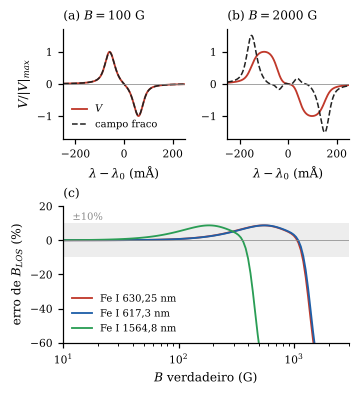

In [6]:
setup(base=8)
fig = plt.figure(figsize=(COLUNA, 3.7))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.25], hspace=0.55, wspace=0.35)
L = sp.LINHAS['Fe I 630,25 nm']; C = sp.C_ZEEMAN * L['g'] * L['lam0']**2
for j, B in enumerate([100, 2000]):
    ax = fig.add_subplot(gs[0, j])
    lam, S = perfis(L, B, 30); xx = (lam - L['lam0']) * 1e3
    prev = -C * B * np.cos(np.deg2rad(30)) * np.gradient(S[0], lam)
    esc = np.abs(S[3]).max()
    ax.plot(xx, S[3]/esc, color=CORES['V'], label='$V$')
    ax.plot(xx, prev/esc, '--', color=CORES['I'], lw=1, label='campo fraco')
    ax.axhline(0, color=CORES['cinza'], lw=0.5); ax.set_xlim(-250, 250); ax.set_xticks([-200, 0, 200])
    ax.set_title(f'({"ab"[j]}) $B = {B}$ G', loc='left'); ax.set_xlabel('$\lambda - \lambda_0$ (mÅ)')
    ax.set_ylim(-1.7, 1.7); virgula(ax, 'y')
    if j == 0: ax.set_ylabel('$V/|V|_{max}$'); ax.legend(frameon=False, loc='lower left', fontsize=6.5, handlelength=1.5)
ax = fig.add_subplot(gs[1, :])
ax.axhspan(-10, 10, color=CORES['cinza'], alpha=0.15, lw=0)
for n in nomes:
    ax.plot(Bs, 100*(res[n]/Bs - 1), color=cores[n], label=n)
ax.axhline(0, color=CORES['cinza'], lw=0.5); ax.set_xscale('log'); ax.set_ylim(-60, 20); ax.set_xlim(10, 3000)
ax.set_xlabel('$B$ verdadeiro (G)'); ax.set_ylabel('erro de $B_{LOS}$ (%)'); ax.set_title('(c)', loc='left')
ax.legend(frameon=False, loc='lower left', fontsize=6.5); ax.text(12, 12, '±10%', color=CORES['cinza'], fontsize=6.5)
virgula(ax, 'y')
salvar(fig, 'fig4_campo_fraco')
setup()

## 4. Efeito do ruído (Seção S6 do material suplementar)

A derivada numérica amplifica o ruído de $I$. Esse ruído entra no denominador $\sum I'^2$ e puxa a estimativa para baixo. Suavizar $I$ antes de derivar (aqui, um filtro de Savitzky-Golay) remove quase todo o viés.

In [7]:
from scipy.signal import savgol_filter
rng = np.random.default_rng(1)
L = sp.LINHAS['Fe I 630,25 nm']
for sig in (1e-3, 3e-3):
    bruto, suave = [], []
    for _ in range(300):
        lam, S = perfis(L, 50, 0)
        In, Vn = S[0] + rng.normal(0, sig, lam.size), S[3] + rng.normal(0, sig, lam.size)
        bruto.append(sp.wfa_blos(lam, In, Vn, L['lam0'], L['g']))
        suave.append(sp.wfa_blos(lam, savgol_filter(In, 51, 3), Vn, L['lam0'], L['g']))
    print(f'ruído {sig:.0e} I_c, B = 50 G: sem suavizar {np.mean(bruto):5.1f} ± {np.std(bruto):.1f} G | suavizando I {np.mean(suave):5.1f} ± {np.std(suave):.1f} G')

ruído 1e-03 I_c, B = 50 G: sem suavizar  45.4 ± 0.3 G | suavizando I  50.2 ± 0.2 G


ruído 3e-03 I_c, B = 50 G: sem suavizar  25.9 ± 0.8 G | suavizando I  50.1 ± 0.5 G


## Exercícios

1. Repita a varredura com $\gamma = 60°$. O limite em $B$ muda? E o limite em $B\cos\gamma$?
2. Restrinja a soma de mínimos quadrados aos flancos da linha (exclua o núcleo). O limite melhora?
3. Implemente a estimativa de $B_\perp$ com `wfa_btrans` e compare seu limite com o de $B_{LOS}$.